# ML Lab Record — Question 1
# Experiment 1: Data Preprocessing

## Write a Python program to preprocess the Titanic dataset (titanic.csv).

(a) Show the dataset's basic details: its size, column names, data types, and summary statistics.

(b) Display the number of missing values in each column.

(c) Fill missing Age values with the median and Embarked values with the mode.

(d) Identify the target column and drop it into a new column.

(e) Identify the categorical features and convert them to numeric form using label encoding.

(f) Identify the outliers using a boxplot. Apply Min-Max normalization to remove outliers.

(g) Split the data into training and test sets and print the shapes of both.

Additional requirement: Print the first five rows of the dataset after each step.

In [31]:
# (a) Show the dataset's basic details: its size, column names, data types, and summary statistics.

import pandas as pd

# Load the dataset
df = pd.read_csv('./titanic.csv')

# Display the first 5 rows
print("First 5 rows:")
print(df.head())

print("<=================================>")

# Display dataset size (total number of cells)
print("Dataset size:")
print(df.size)

print("<=================================>")

# Display dataset shape (rows, columns)
print("Dataset shape:")
print(df.shape)

print("<=================================>")

# Display column names
print("Column names:")
print(df.columns)

print("<=================================>")

# Display data types of each column
print("Data types:")
print(df.dtypes)

print("<=================================>")

# Display summary statistics
print("Summary statistics:")
print(df.describe())

print("<=================================>")

# Display the last 5 rows
print("Last 5 rows:")
print(df.tail())

First 5 rows:
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  
<=================================>
Dataset size:
13365
<=================================>
Dataset shape:
(891, 15)
<=================================>
Column names:
Index(['survived', 'pclass', 'sex', 'a

In [37]:
# (b) Display the number of missing values in each column.

# Display the number of missing values in each column
print("Missing values in each column:")
print(df.isnull().sum())

print("<=================================>")

# Display the total number of missing values
print("Total missing values:")
print(df.isnull().sum().sum())

Missing values in each column:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64
<=================================>
Total missing values:
869


In [43]:
# (c) Fill missing Age values with the median and Embarked values with the mode.

# Fill missing Age values with the median
df['age'] = df['age'].fillna(df['age'].median())

# Fill missing Embarked values with the mode
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])

# Display the first 5 rows
print("Dataset after handling missing values:")
print(df.head())

print("<=================================>")

# Check missing values again
print("Missing values after handling:")
print(df.isnull().sum())

Dataset after handling missing values:
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  
<=================================>
Missing values after handling:
survived         0
pclass           0
sex              0
age              0
sibsp            0
parch            0

In [45]:
# (d) Identify the target column and drop it into a new column.

# Separate input features and target variable
X = df.drop('survived', axis=1)
y = df['survived']

# Display the input features
print("Input features (X):")
print(X.head())

print("<=================================>")

# Display the target variable
print("Target variable (y):")
print(y.head())

print("<=================================>")

# Display the shapes
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Input features (X):
   pclass     sex   age  sibsp  parch     fare embarked  class    who  \
0       3    male  22.0      1      0   7.2500        S  Third    man   
1       1  female  38.0      1      0  71.2833        C  First  woman   
2       3  female  26.0      0      0   7.9250        S  Third  woman   
3       1  female  35.0      1      0  53.1000        S  First  woman   
4       3    male  35.0      0      0   8.0500        S  Third    man   

   adult_male deck  embark_town alive  alone  
0        True  NaN  Southampton    no  False  
1       False    C    Cherbourg   yes  False  
2       False  NaN  Southampton   yes   True  
3       False    C  Southampton   yes  False  
4        True  NaN  Southampton    no   True  
<=================================>
Target variable (y):
0    0
1    1
2    1
3    1
4    0
Name: survived, dtype: int64
<=================================>
Shape of X: (891, 14)
Shape of y: (891,)


In [48]:
# (e) Identify the categorical features and convert them to numeric form using label encoding.


from sklearn.preprocessing import LabelEncoder

# Encode categorical columns
le = LabelEncoder()

for column in X.select_dtypes(include=['object']).columns:
    X[column] = X[column].fillna('Unknown')
    X[column] = le.fit_transform(X[column])

# Display the first 5 rows after encoding
print("Dataset after label encoding:")
print(X.head())

print("<=================================>")

# Display data types
print("Data types after encoding:")
print(X.dtypes)

Dataset after label encoding:
   pclass  sex   age  sibsp  parch     fare  embarked  class  who  adult_male  \
0       3    1  22.0      1      0   7.2500         2      2    1        True   
1       1    0  38.0      1      0  71.2833         0      0    2       False   
2       3    0  26.0      0      0   7.9250         2      2    2       False   
3       1    0  35.0      1      0  53.1000         2      0    2       False   
4       3    1  35.0      0      0   8.0500         2      2    1        True   

   deck  embark_town  alive  alone  
0     7            2      0  False  
1     2            0      1  False  
2     7            2      1   True  
3     2            2      1  False  
4     7            2      0   True  
<=================================>
Data types after encoding:
pclass           int64
sex              int64
age            float64
sibsp            int64
parch            int64
fare           float64
embarked         int64
class            int64
who           

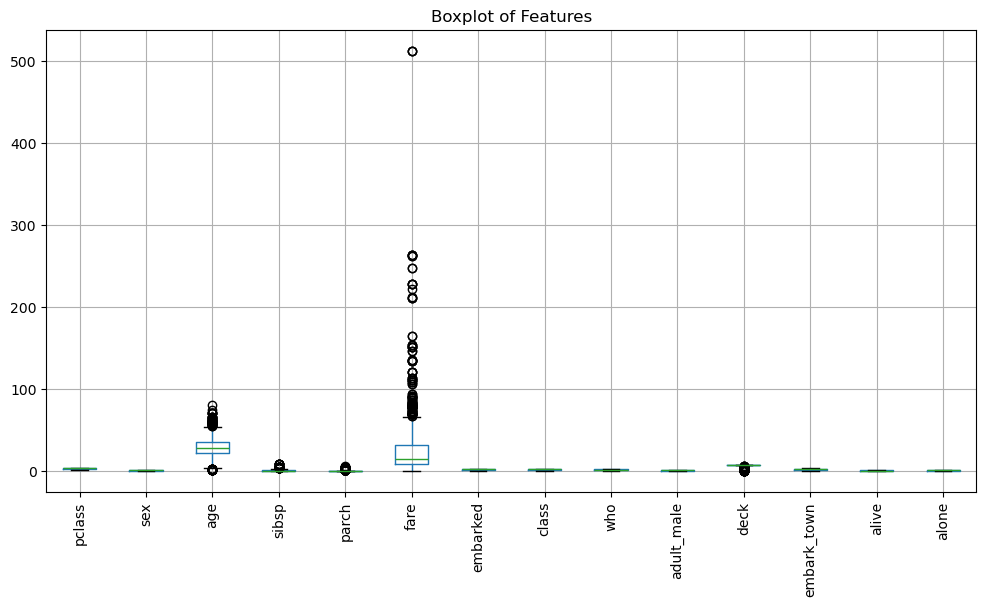

<=================================>
Dataset after Min-Max normalization:
   pclass  sex       age  sibsp  parch      fare  embarked  class  who  \
0     1.0  1.0  0.271174  0.125    0.0  0.014151       1.0    1.0  0.5   
1     0.0  0.0  0.472229  0.125    0.0  0.139136       0.0    0.0  1.0   
2     1.0  0.0  0.321438  0.000    0.0  0.015469       1.0    1.0  1.0   
3     0.0  0.0  0.434531  0.125    0.0  0.103644       1.0    0.0  1.0   
4     1.0  1.0  0.434531  0.000    0.0  0.015713       1.0    1.0  0.5   

   adult_male      deck  embark_town  alive  alone  
0         1.0  1.000000     0.666667    0.0    0.0  
1         0.0  0.285714     0.000000    1.0    0.0  
2         0.0  1.000000     0.666667    1.0    1.0  
3         0.0  0.285714     0.666667    1.0    0.0  
4         1.0  1.000000     0.666667    0.0    1.0  


In [49]:
# (f) Identify the outliers using a boxplot. Apply Min-Max normalization to remove outliers.

import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

# Display boxplots to identify outliers
plt.figure(figsize=(12, 6))
X.boxplot()
plt.xticks(rotation=90)
plt.title("Boxplot of Features")
plt.show()

print("<=================================>")

# Apply Min-Max normalization
scaler = MinMaxScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns
)

# Display the first 5 rows after normalization
print("Dataset after Min-Max normalization:")
print(X_scaled.head())

In [52]:
# (g) Split the data into training and test sets and print the shapes of both.

from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42
)

# Display the shapes of the datasets
print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training features shape: (712, 14)
Testing features shape: (179, 14)
Training target shape: (712,)
Testing target shape: (179,)


# 2. Principal Component Analysis (PCA)
## Write a Python program to apply PCA on the Iris dataset to reduce it from 4 features to 2:

(a) Standardize and plot a scatter plot before applying PCA.

(b) Print the explained variance ratio of each principal component and the total variance retained.

(c) Print the first five rows of the reduced data.

(d) Plot the reduced data as a 2D scatter plot with a different colour for each
species.

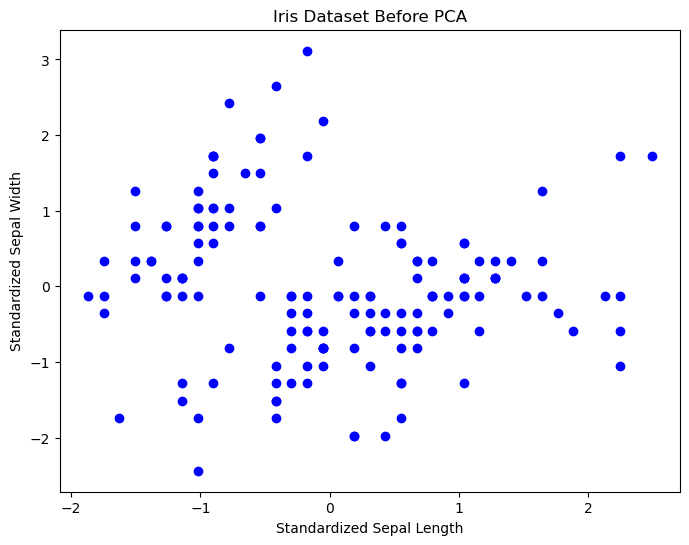

In [54]:
# (a) Standardize and plot the data before PCA
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# Load the Iris dataset from CSV
columns = [
    'SepalLength',
    'SepalWidth',
    'PetalLength',
    'PetalWidth',
    'Species'
]

df = pd.read_csv('./iris.csv', names=columns)

# Separate features and target
X = df.iloc[:, 0:4]
y = df['Species']

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Plot before applying PCA
plt.figure(figsize=(8, 6))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], color='blue')

plt.xlabel('Standardized Sepal Length')
plt.ylabel('Standardized Sepal Width')
plt.title('Iris Dataset Before PCA')
plt.show()

In [56]:
# (b) Print the explained variance ratio and total variance retained
from sklearn.decomposition import PCA

# Apply PCA to reduce 4 features to 2
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Print explained variance ratioPrincipal Component Analysis (PCA
print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

# Print total variance retained
print("Total variance retained:")
print(pca.explained_variance_ratio_.sum())

Explained variance ratio:
[0.72770452 0.23030523]
Total variance retained:
0.9580097536148199


In [58]:
# (c) Print the first five rows of the reduced data
# Convert reduced data into a DataFrame
pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2']
)

# Print first 5 rows
print("First 5 rows of reduced data:")
print(pca_df.head())

First 5 rows of reduced data:
        PC1       PC2
0 -2.264542  0.505704
1 -2.086426 -0.655405
2 -2.367950 -0.318477
3 -2.304197 -0.575368
4 -2.388777  0.674767


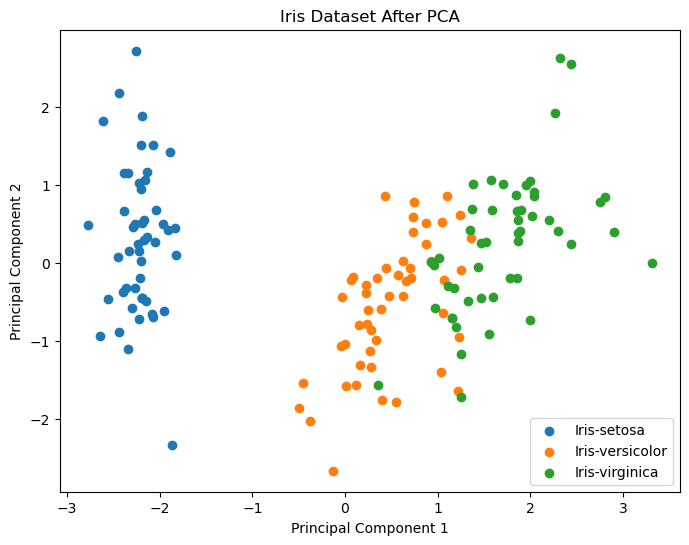

In [59]:
# (d) Plot the reduced data with a different colour for each species 
# Add species labels to the reduced dataset
pca_df['Species'] = y.values

# Plot the reduced data
plt.figure(figsize=(8, 6))

for species in pca_df['Species'].unique():
    subset = pca_df[pca_df['Species'] == species]

    plt.scatter(
        subset['PC1'],
        subset['PC2'],
        label=species
    )

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Iris Dataset After PCA')
plt.legend()
plt.show()

# 3. Write a program to perform logistic regression on the Wine dataset.

In [62]:
# (a) Load and inspect the Wine dataset

import pandas as pd

columns = [
    'Class', 'Alcohol', 'Malic_acid', 'Ash',
    'Alcalinity_of_ash', 'Magnesium', 'Total_phenols',
    'Flavanoids', 'Nonflavanoid_phenols', 'Proanthocyanins',
    'Color_intensity', 'Hue', 'OD280_OD315', 'Proline'
]

df = pd.read_csv('./wine.csv', header=None, names=columns)

print("First 5 rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nDataset information:")
print(df.info())

print("\nClass distribution:")
print(df['Class'].value_counts())

First 5 rows:
   Class  Alcohol  Malic_acid   Ash  Alcalinity_of_ash  Magnesium  \
0      1    14.23        1.71  2.43               15.6        127   
1      1    13.20        1.78  2.14               11.2        100   
2      1    13.16        2.36  2.67               18.6        101   
3      1    14.37        1.95  2.50               16.8        113   
4      1    13.24        2.59  2.87               21.0        118   

   Total_phenols  Flavanoids  Nonflavanoid_phenols  Proanthocyanins  \
0           2.80        3.06                  0.28             2.29   
1           2.65        2.76                  0.26             1.28   
2           2.80        3.24                  0.30             2.81   
3           3.85        3.49                  0.24             2.18   
4           2.80        2.69                  0.39             1.82   

   Color_intensity   Hue  OD280_OD315  Proline  
0             5.64  1.04         3.92     1065  
1             4.38  1.05         3.40     1050

In [63]:
# (b) Separate features and target 
X = df.drop('Class', axis=1)
y = df['Class']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (178, 13)
Target shape: (178,)


In [64]:
# (c) Split the dataset into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (142, 13)
Testing data: (36, 13)


In [65]:
# (d) Standardize the features
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Features standardized successfully.")

Features standardized successfully.


In [66]:
# (e) Train the Logistic Regression model
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [67]:
# (f) Predict and evaluate the model

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = model.predict(X_test_scaled)

print("Predictions:")
print(y_pred)

print("\nActual values:")
print(y_test.values)

print("\nAccuracy:")
print(accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Predictions:
[1 2 1 2 2 1 1 2 2 3 2 3 1 3 1 2 2 1 2 1 2 2 1 1 2 2 1 3 2 3 1 3 2 3 3 3]

Actual values:
[1 3 1 2 2 1 1 2 2 3 2 3 1 3 1 2 2 1 2 1 2 2 1 1 2 2 1 3 2 3 1 3 2 3 3 3]

Accuracy:
0.9722222222222222

Confusion Matrix:
[[12  0  0]
 [ 0 14  0]
 [ 0  1  9]]

Classification Report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        12
           2       0.93      1.00      0.97        14
           3       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



# 4. Support Vector Machine (SVM)
## Write a Python program to classify tumours as malignant or benign using SVM:
(a) Scale the features using StandardScaler.

(b) Train two SVM models using linear and RBF kernels and print the accuracy of both.

(c) Display the confusion matrix and print accuracy,precision, recall, F1-score

(d) Print the classification report.

Dataset: Breast Cancer Wisconsin (sklearn.datasets.load_breast_cancer)

In [69]:
#(a) Scale the features using StandardScaler

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

columns = [
    'ID', 'Diagnosis',
    'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
    'smoothness_mean', 'compactness_mean', 'concavity_mean',
    'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean',
    'radius_se', 'texture_se', 'perimeter_se', 'area_se',
    'smoothness_se', 'compactness_se', 'concavity_se',
    'concave_points_se', 'symmetry_se', 'fractal_dimension_se',
    'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst',
    'smoothness_worst', 'compactness_worst', 'concavity_worst',
    'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst'
]

df = pd.read_csv('./breast_cancer.csv', header=None, names=columns)

# Separate features and target
X = df.drop(['ID', 'Diagnosis'], axis=1)
y = df['Diagnosis']

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardize features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Features scaled successfully.")
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Features scaled successfully.
Training data shape: (455, 30)
Testing data shape: (114, 30)


In [72]:
# (b) Train linear and RBF SVM models and print accuracy

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Linear kernel
linear_model = SVC(kernel='linear')
linear_model.fit(X_train_scaled, y_train)

linear_pred = linear_model.predict(X_test_scaled)

linear_accuracy = accuracy_score(y_test, linear_pred)

# RBF kernel
rbf_model = SVC(kernel='rbf')
rbf_model.fit(X_train_scaled, y_train)

rbf_pred = rbf_model.predict(X_test_scaled)

rbf_accuracy = accuracy_score(y_test, rbf_pred)

print("Linear SVM Accuracy:", linear_accuracy)
print("RBF SVM Accuracy:", rbf_accuracy)

Linear SVM Accuracy: 0.9649122807017544
RBF SVM Accuracy: 0.9736842105263158


In [75]:
# (c) Display confusion matrix and print accuracy, precision, recall, F1-score

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Evaluate Linear SVM
print("LINEAR SVM")
print("Confusion Matrix:")
print(confusion_matrix(y_test, linear_pred))

print("Accuracy:", accuracy_score(y_test, linear_pred))
print("Precision:", precision_score(y_test, linear_pred, pos_label='M'))
print("Recall:", recall_score(y_test, linear_pred, pos_label='M'))
print("F1-score:", f1_score(y_test, linear_pred, pos_label='M'))

# Evaluate RBF SVM
print("\nRBF SVM")
print("Confusion Matrix:")
print(confusion_matrix(y_test, rbf_pred))

print("Accuracy:", accuracy_score(y_test, rbf_pred))
print("Precision:", precision_score(y_test, rbf_pred, pos_label='M'))
print("Recall:", recall_score(y_test, rbf_pred, pos_label='M'))
print("F1-score:", f1_score(y_test, rbf_pred, pos_label='M'))

LINEAR SVM
Confusion Matrix:
[[72  0]
 [ 4 38]]
Accuracy: 0.9649122807017544
Precision: 1.0
Recall: 0.9047619047619048
F1-score: 0.95

RBF SVM
Confusion Matrix:
[[72  0]
 [ 3 39]]
Accuracy: 0.9736842105263158
Precision: 1.0
Recall: 0.9285714285714286
F1-score: 0.9629629629629629


In [76]:
# (d) Print the classification report

from sklearn.metrics import classification_report

print("LINEAR SVM Classification Report:")
print(classification_report(y_test, linear_pred))

print("\nRBF SVM Classification Report:")
print(classification_report(y_test, rbf_pred))

LINEAR SVM Classification Report:
              precision    recall  f1-score   support

           B       0.95      1.00      0.97        72
           M       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114


RBF SVM Classification Report:
              precision    recall  f1-score   support

           B       0.96      1.00      0.98        72
           M       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



# 5. K-Nearest Neighbours (KNN)
## Write a Python program to implement KNN classification on the Iris dataset

(a) Scale the features using StandardScaler.

(b) Classify the test set and print the correct and wrong predictions.

(c) Vary k from 1 to 15, plot accuracy against k, and report the best value of k.

In [78]:
# (a) Scale the features using StandardScaler.
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

columns = [
    'SepalLength', 'SepalWidth',
    'PetalLength', 'PetalWidth', 'Species'
]

df = pd.read_csv('./iris.csv', header=None, names=columns)

X = df.drop('Species', axis=1)
y = df['Species']

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardize the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Features standardized successfully.")
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Features standardized successfully.
Training data shape: (120, 4)
Testing data shape: (30, 4)


In [79]:
# (b) Classify the test set and print correct and wrong predictions

from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)

# Display correct and wrong predictions
print("CORRECT PREDICTIONS")

for actual, predicted in zip(y_test, y_pred):
    if actual == predicted:
        print("Actual:", actual, "| Predicted:", predicted)

print("\nWRONG PREDICTIONS")

for actual, predicted in zip(y_test, y_pred):
    if actual != predicted:
        print("Actual:", actual, "| Predicted:", predicted)

CORRECT PREDICTIONS
Actual: Iris-setosa | Predicted: Iris-setosa
Actual: Iris-virginica | Predicted: Iris-virginica
Actual: Iris-versicolor | Predicted: Iris-versicolor
Actual: Iris-versicolor | Predicted: Iris-versicolor
Actual: Iris-setosa | Predicted: Iris-setosa
Actual: Iris-versicolor | Predicted: Iris-versicolor
Actual: Iris-setosa | Predicted: Iris-setosa
Actual: Iris-setosa | Predicted: Iris-setosa
Actual: Iris-virginica | Predicted: Iris-virginica
Actual: Iris-versicolor | Predicted: Iris-versicolor
Actual: Iris-virginica | Predicted: Iris-virginica
Actual: Iris-virginica | Predicted: Iris-virginica
Actual: Iris-virginica | Predicted: Iris-virginica
Actual: Iris-versicolor | Predicted: Iris-versicolor
Actual: Iris-setosa | Predicted: Iris-setosa
Actual: Iris-setosa | Predicted: Iris-setosa
Actual: Iris-setosa | Predicted: Iris-setosa
Actual: Iris-versicolor | Predicted: Iris-versicolor
Actual: Iris-versicolor | Predicted: Iris-versicolor
Actual: Iris-setosa | Predicted: Iris-s

Best value of k: 1
Best accuracy: 0.9666666666666667


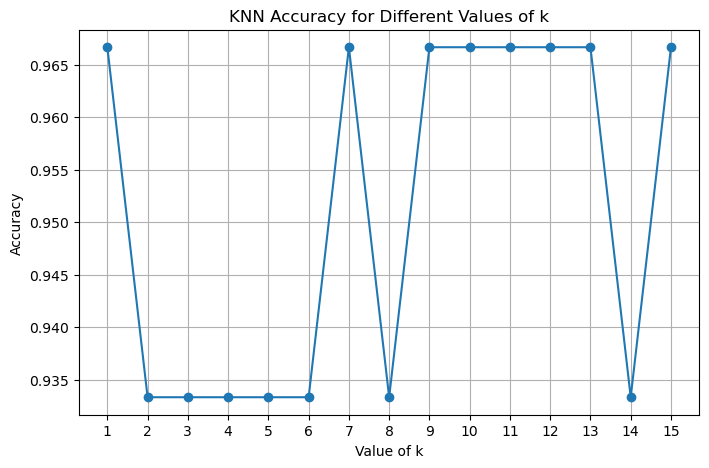

In [80]:
# (c) Vary k from 1 to 15, plot accuracy, and report best k
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

k_values = range(1, 16)
accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)

    y_pred = knn.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, y_pred)
    accuracies.append(accuracy)

# Find the best k
best_index = accuracies.index(max(accuracies))
best_k = list(k_values)[best_index]
best_accuracy = accuracies[best_index]

print("Best value of k:", best_k)
print("Best accuracy:", best_accuracy)

# Plot accuracy against k
plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, marker='o')

plt.xlabel("Value of k")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy for Different Values of k")
plt.xticks(range(1, 16))
plt.grid(True)

plt.show()

# 6. Decision Tree
## Write a classification program for implementing decision tree using the playtennis dataset

(a) Encode the categorical attributes and build the decision tree.

(b) Print the tree in text form using export_text and display it graphically using plot_tree.

(c) Print the accuracy of the tree on the training data.

(d) Classify the new sample: Outlook = Sunny, Temperature = Cool, Humidity = High, Wind = Strong.

Dataset: playtennis.csv (14 rows

In [82]:
# (a) Encode categorical attributes and build the decision tree
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier

# Load dataset
df = pd.read_csv('./playtennis.csv')

print("First 5 rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

# Clean column names
df.columns = df.columns.str.strip()

# Encode categorical columns
encoders = {}

for column in df.columns:
    encoder = LabelEncoder()
    df[column] = encoder.fit_transform(df[column].astype(str).str.strip())
    encoders[column] = encoder

print("\nEncoded dataset:")
print(df)

# Separate features and target
X = df.drop('Play Tennis', axis=1)
y = df['Play Tennis']

# Build decision tree
model = DecisionTreeClassifier(criterion='entropy', random_state=42)
model.fit(X, y)

print("\nDecision tree built successfully.")

First 5 rows:
    Outlook Temperature Humidity    Wind Play Tennis
0     Sunny         Hot     High    Weak          No
1     Sunny         Hot     High  Strong          No
2  Overcast         Hot     High    Weak         Yes
3      Rain        Mild     High    Weak         Yes
4      Rain        Cool   Normal    Weak         Yes

Dataset shape:
(14, 5)

Encoded dataset:
    Outlook  Temperature  Humidity  Wind  Play Tennis
0         2            1         0     1            0
1         2            1         0     0            0
2         0            1         0     1            1
3         1            2         0     1            1
4         1            0         1     1            1
5         1            0         1     0            0
6         0            0         1     0            1
7         2            2         0     1            0
8         2            0         1     1            1
9         1            2         1     1            1
10        2            2        

Decision Tree in Text Form:
|--- Outlook <= 0.50
|   |--- class: 1
|--- Outlook >  0.50
|   |--- Humidity <= 0.50
|   |   |--- Outlook <= 1.50
|   |   |   |--- Wind <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- Wind >  0.50
|   |   |   |   |--- class: 1
|   |   |--- Outlook >  1.50
|   |   |   |--- class: 0
|   |--- Humidity >  0.50
|   |   |--- Wind <= 0.50
|   |   |   |--- Temperature <= 1.00
|   |   |   |   |--- class: 0
|   |   |   |--- Temperature >  1.00
|   |   |   |   |--- class: 1
|   |   |--- Wind >  0.50
|   |   |   |--- class: 1



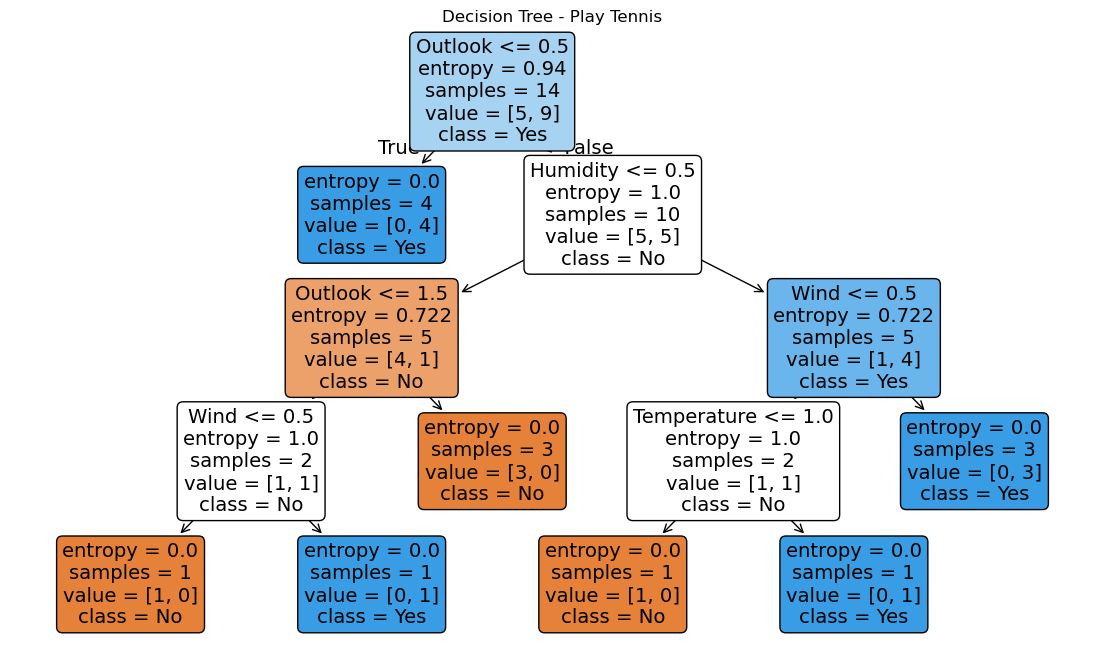

In [83]:
# (b) Print the tree in text form and display it graphically

from sklearn.tree import export_text, plot_tree
import matplotlib.pyplot as plt

# Print tree in text form
tree_text = export_text(model, feature_names=list(X.columns))

print("Decision Tree in Text Form:")
print(tree_text)

# Display tree graphically
plt.figure(figsize=(14, 8))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=encoders['Play Tennis'].classes_,
    filled=True,
    rounded=True
)

plt.title("Decision Tree - Play Tennis")
plt.show()

In [84]:
# (c) Print training accuracy

from sklearn.metrics import accuracy_score

y_pred = model.predict(X)

accuracy = accuracy_score(y, y_pred)

print("Training Accuracy:", accuracy)
print("Training Accuracy (%):", accuracy * 100)

Training Accuracy: 1.0
Training Accuracy (%): 100.0


In [85]:
# (d) Classify the new sample

# New sample
new_sample = pd.DataFrame(
    [['Sunny', 'Cool', 'High', 'Strong']],
    columns=['Outlook', 'Temperature', 'Humidity', 'Wind']
)

# Encode using the same encoders from training
for column in new_sample.columns:
    new_sample[column] = encoders[column].transform(
        new_sample[column].astype(str).str.strip()
    )

# Predict
prediction = model.predict(new_sample)

# Convert encoded prediction back to original label
result = encoders['Play Tennis'].inverse_transform(prediction)

print("New Sample:")
print("Outlook = Sunny")
print("Temperature = Cool")
print("Humidity = High")
print("Wind = Strong")

print("\nPredicted Class:", result[0])

New Sample:
Outlook = Sunny
Temperature = Cool
Humidity = High
Wind = Strong

Predicted Class: No


# 7. K-Means Clustering
## Write a Python program to implement K-Means clustering using the Mall Customers dataset

(a) Use the Elbow method (k = 1 to 10) to find the optimal number of clusters and plot the elbow curve.

(b) Apply K-Means with the optimal k and plot the clusters with their centroids marked

In [86]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Load dataset
df = pd.read_csv('./Mall_Customers.csv')

print("First 5 rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nDataset information:")
print(df.info())

First 5 rows:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Dataset shape:
(200, 5)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB
None


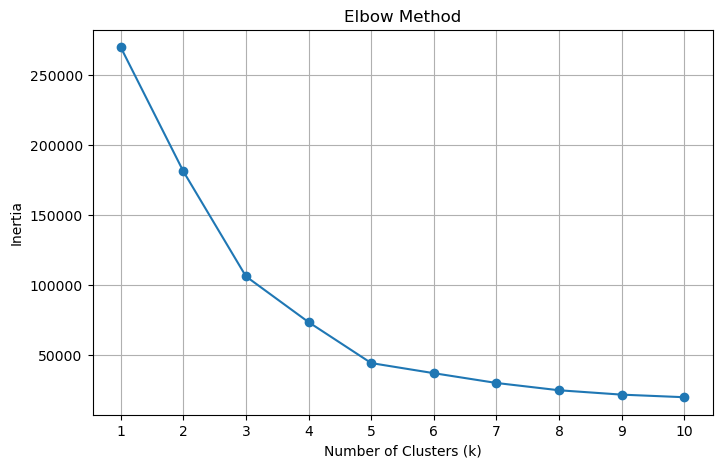

In [87]:
# (a) Elbow method — k = 1 to 10

# Select Annual Income and Spending Score
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

# Calculate inertia for k = 1 to 10
inertia_values = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        random_state=42,
        n_init=10
    )

    kmeans.fit(X)
    inertia_values.append(kmeans.inertia_)

# Plot elbow curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia_values, marker='o')

plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.xticks(range(1, 11))
plt.grid(True)

plt.show()

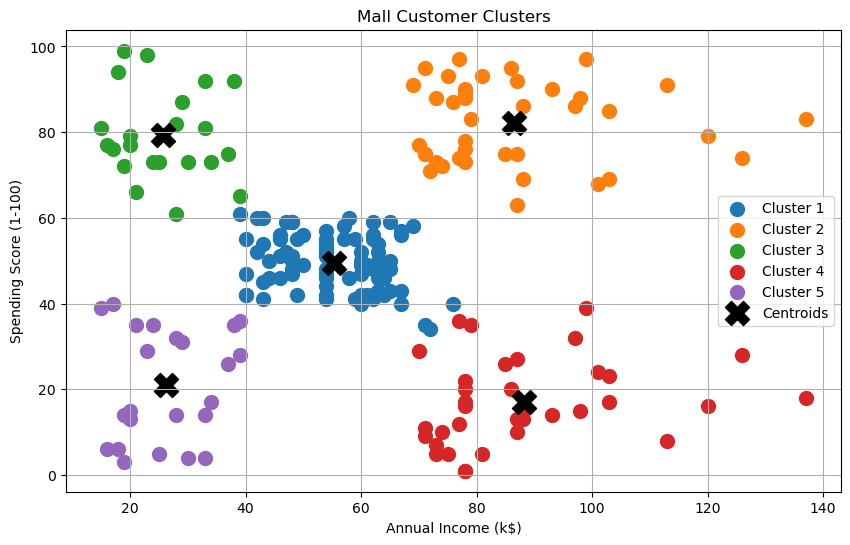

In [88]:
# (b) Apply K-Means and plot clusters with centroids

# Apply K-Means using optimal k
optimal_k = 5

kmeans = KMeans(
    n_clusters=optimal_k,
    init='k-means++',
    random_state=42,
    n_init=10
)

# Assign cluster labels
y_kmeans = kmeans.fit_predict(X)

# Plot clusters
plt.figure(figsize=(10, 6))

for i in range(optimal_k):
    plt.scatter(
        X.iloc[y_kmeans == i, 0],
        X.iloc[y_kmeans == i, 1],
        s=100,
        label=f'Cluster {i + 1}'
    )

# Plot centroids
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    s=300,
    marker='X',
    color='black',
    label='Centroids'
)

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Mall Customer Clusters')
plt.legend()
plt.grid(True)

plt.show()

# 8. Artificial Neural Network (ANN)
## Write a Python program to build a multilayer perceptron using MLPClassifier to predict diabetes:

(a) Scale the features using StandardScaler.

(b) Build the network with two hidden layers (16 and 8 neurons) using ReLU activation and train for up to 500 iterations.

(c) Plot the training loss curve using loss_curve_.

(d) Print the test accuracy and confusion matrix.

Dataset: diabetes.csv (Pima Indians Diabetes, 768 rows)

    

In [92]:
import pandas as pd

# Load dataset
df = pd.read_csv('./diabetes.csv')

print("First 5 rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nDataset information:")
print(df.info())

First 5 rows:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Dataset shape:
(768, 9)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-

In [93]:
# (a) Scale the features using StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate features and target
X = df.drop('Outcome', axis=1)
y = df['Outcome']

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardize features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Features standardized successfully.")
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Features standardized successfully.
Training data shape: (614, 8)
Testing data shape: (154, 8)


In [94]:
# (b) Build and train the MLP neural network 

from sklearn.neural_network import MLPClassifier

# Build the neural network
mlp = MLPClassifier(
    hidden_layer_sizes=(16, 8),
    activation='relu',
    max_iter=500,
    random_state=42
)

# Train the model
mlp.fit(X_train_scaled, y_train)

print("ANN model trained successfully.")

ANN model trained successfully.


/home/mrrobot/.local/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


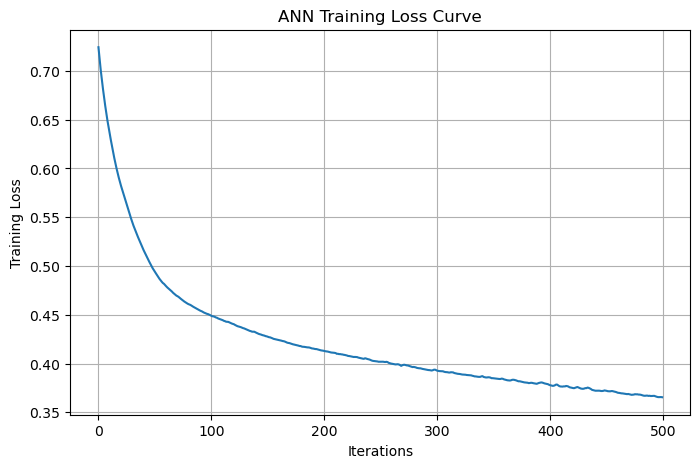

In [95]:
# (c) Plot the training loss curve using loss_curve_

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(mlp.loss_curve_)

plt.xlabel('Iterations')
plt.ylabel('Training Loss')
plt.title('ANN Training Loss Curve')
plt.grid(True)

plt.show()

In [96]:
# (d) Print test accuracy and confusion matrix
from sklearn.metrics import accuracy_score, confusion_matrix

# Predict test data
y_pred = mlp.predict(X_test_scaled)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Test Accuracy:", accuracy)
print("Test Accuracy (%):", accuracy * 100)

# Display confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

Test Accuracy: 0.7142857142857143
Test Accuracy (%): 71.42857142857143

Confusion Matrix:
[[78 22]
 [22 32]]


# 9. Convolutional Neural Network (CNN)
## Write a Python program to build a CNN using Keras to classify handwritten digits:

(a) Reshape the images to 8×8×1 and normalize the pixel values.

(b) Build the model with one Conv2D layer (16 filters, 3×3), one MaxPooling layer, a Flatten layer, a Dense hidden layer and a softmax output layer.

(c) Train for 20 epochs and plot the accuracy curve.

(d) Print the test accuracy and the predicted versus actual labels for five test images.

Dataset: Digits (sklearn.datasets.load_digits, 1,797 images of 8×8 pixels)

In [108]:
# (a) Reshape images and normalize pixel values
from sklearn.datasets import load_digits

digits = load_digits()
X = digits.images
y = digits.target

X = X.reshape(-1, 8, 8, 1)
X = X / 16.0

In [109]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train, y_train,
    epochs=20,
    validation_split=0.2
)

AttributeError: 'DecisionTreeClassifier' object has no attribute 'compile'

In [110]:
# (c) Plot the accuracy curve

import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('CNN Accuracy Curve')
plt.legend()
plt.show()

NameError: name 'history' is not defined

In [103]:
# (d) Test accuracy and five predictions

import numpy as np

test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print("Test Accuracy:", test_accuracy)

predictions = model.predict(X_test[:5], verbose=0)
predicted_labels = np.argmax(predictions, axis=1)

print("\nPredicted vs Actual Labels:")
for i in range(5):
    print(
        f"Image {i + 1}: Predicted = {predicted_labels[i]}, "
        f"Actual = {y_test[i]}"
    )

AttributeError: 'DecisionTreeClassifier' object has no attribute 'evaluate'